# Xi sensitivity: mean gain and uncertainty

Read-only xi diagnostics for selecting the next weekly batch, trained on observations through `CURRENT_WEEK`. The seeded Sobol screening pool, local candidates and one fitted GP per function are shared across alpha values by `suggest_ei_sweep`; each xi is then polished with L-BFGS-B, using the per-function kernels configured in `KERNEL_NAMES_BY_FUNCTION`. These are model-based comparisons, not evaluated outcomes or guaranteed global optima. Nothing is exported from this notebook.

## 1. Setup, paths and shared data loading

Collect saved predictions and observations through `CURRENT_WEEK`, then filter the history to `WEEKS`. The shared collector validates input coordinates, prediction lengths, means and standard deviations. `historical_results`, `previous_best`, `expected_best`, `observed_best` and `residuals` retain the historical calibration context. Training observations are separately capped at `WEEKS[-1]`; `LENGTH_CAPS`, `ALPHA_VALUES` and derived `XI_VALUES` prepare the next-candidate fits.

`ALPHA_GRID` is dimensionless; each function uses `xi = alpha * std(training outputs)`. `MIN_PROBABILITY` is an adjustable visual flag, not a selection constraint. The configured Sobol screening pool and local candidate count are used by default.


In [1]:
%matplotlib inline
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ndtr

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.acquisition import expected_best_output
from bayesian_bbo.history import load_weekly_history
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.optimisation import BayesianOptimizer, OptimisationConfig

CURRENT_WEEK = 6
WEEKS = tuple(range(1, CURRENT_WEEK + 1))
FUNCTION_IDS = tuple(FUNCTION_SPECS)
ALPHA_GRID = np.array([0.0, 0.025, 0.05, 0.1, 0.2, 0.3, 0.4])
MIN_PROBABILITY = 0.20
N_CANDIDATES = CONFIG["candidates"]
ALPHA_VALUES = {
    1: 0.1, 2: 0.1, 3: 0.2, 4: 0.0,
    5: 0.1, 6: 0.1, 7: 0.1, 8: 0.0,
}
LENGTH_CAPS = CONFIG["length_caps"]
KERNEL_NAMES_BY_FUNCTION = {
    1: "Rational Quadratic",
    2: "RBF",
    3: "Rational Quadratic",
    4: "Matérn 3/2",
    5: "Rational Quadratic",
    6: "Rational Quadratic",
    7: "Matérn 3/2",
    8: "Rational Quadratic",
}
KERNEL_FACTORIES = {
    function_id: (
        lambda dimension, length_cap, name=kernel_name:
        make_comparison_kernels(dimension, length_cap)[name]
    )
    for function_id, kernel_name in KERNEL_NAMES_BY_FUNCTION.items()
}

data_candidates = [Path("../../data"), Path("data"), Path("../data")]
matches = [path.resolve() for path in data_candidates if (path / "function_1").is_dir()]
if not matches:
    raise FileNotFoundError("Could not find the data directory from the notebook working directory.")
data_root = matches[0]
history = load_weekly_history(data_root, current_week=CURRENT_WEEK, function_ids=FUNCTION_IDS)
TRAINING_OBSERVATIONS = {
    function_id: observations.through_week(WEEKS[-1])
    for function_id, observations in history.observations.items()
}
XI_VALUES = {
    function_id: ALPHA_VALUES[function_id] * np.std(observations.outputs)
    for function_id, observations in TRAINING_OBSERVATIONS.items()
}

historical_results = history.records.loc[history.records.week.isin(WEEKS)].copy()
previous_best = historical_results.pivot(index="function_id", columns="week", values="previous_best").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
expected_best = historical_results.pivot(index="function_id", columns="week", values="expected_best").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
observed_best = historical_results.pivot(index="function_id", columns="week", values="observed_best").reindex(index=FUNCTION_IDS, columns=WEEKS).to_numpy()
residuals = historical_results.groupby("function_id").residual.apply(list).to_dict()
print(f"Data root: {data_root}; training through week {WEEKS[-1]}; candidates: {N_CANDIDATES:,}")
print(f"Kernel map: {KERNEL_NAMES_BY_FUNCTION}")
display(historical_results.round(5))

Data root: /home/pabloncho/repositories/bayesian-bbo/data; training through week 6; candidates: 1,000,000
Kernel map: {1: 'Rational Quadratic', 2: 'RBF', 3: 'Rational Quadratic', 4: 'Matérn 3/2', 5: 'Rational Quadratic', 6: 'Rational Quadratic', 7: 'Matérn 3/2', 8: 'Rational Quadratic'}


,function_id,week,candidate,previous_best,expected_best,observed_best,expected_mean,expected_std,observed_output,residual,acquisition_score,acquisition_settings
0,1,1,"(0.835456, 0.75533)",0.00000,0.00119,0.00000,0.00116,0.00082,-0.00000,-1.41138,0.00277,"{'name': 'ucb', 'kappa': 1.96}"
1,2,1,"(0.802058, 0.932779)",0.61121,0.64433,0.61121,0.52356,0.17088,0.12634,-2.32453,0.85850,"{'name': 'ucb', 'kappa': 1.96}"
2,3,1,"(0.194638, 0.363906, 0.466721)",-0.03484,-0.01969,-0.00589,-0.07258,0.07610,-0.00589,0.87632,0.07658,"{'name': 'ucb', 'kappa': 1.96}"
3,4,1,"(0.528998, 0.424017, 0.506366, 0.277697)",-4.02554,-3.46456,-3.33639,-8.97341,5.53082,-3.33639,1.01920,1.86699,"{'name': 'ucb', 'kappa': 1.96}"
4,5,1,"(0.29667, 0.806944, 0.906495, 0.936907)",1088.85962,1090.58998,1397.54511,689.50145,200.32226,1397.54511,3.53452,1082.13308,"{'name': 'ucb', 'kappa': 1.96}"
5,6,1,"(0.776415, 0.143718, 0.670225, 0.693095, 0.060...",-0.71426,-0.66955,-0.71426,-0.92666,0.30778,-0.74707,0.58348,-0.32341,"{'name': 'ucb', 'kappa': 1.96}"
6,7,1,"(0.167857, 0.467652, 0.068225, 0.169714, 0.420...",1.36497,1.36499,1.36497,0.30715,0.30125,1.08542,2.58350,0.89759,"{'name': 'ucb', 'kappa': 1.96}"
7,8,1,"(0.133138, 0.57364, 0.420506, 0.497998, 0.8321...",9.59848,9.61884,9.59848,8.08213,0.93237,9.42806,1.44356,9.90957,"{'name': 'ucb', 'kappa': 1.96}"
8,1,2,"(0.7021, 0.165487)",0.00000,0.00041,0.00000,0.00014,0.00085,-0.00000,-0.16665,0.00036,"{'name': 'ei', 'xi': 0.00010366701219489613, '..."
9,2,2,"(0.689383, 0.099113)",0.61121,0.63208,0.61121,0.60813,0.05608,0.60042,-0.13750,0.01214,"{'name': 'ei', 'xi': 0.02169598518452902, 'bes..."


## 2. Shared-pool EI sweep and prediction diagnostics

For each function, hold the GP, seed, observations and candidate pool fixed while varying alpha. All following gains are **expected**, not observed.

At each selected point, let $Y\sim\mathcal N(\mu,\sigma^2)$ and let $f^*$ be the incumbent:

- Mean gain: $G=\max(\mu-f^*,0)$.
- Expected improvement relative to the incumbent: $\mathrm{EI}_0=\mathbb E[(Y-f^*)_+]$.
- Uncertainty premium: $U=\mathrm{EI}_0-G\ge0$, with share $U/\mathrm{EI}_0$ when EI is positive.
- Probability of beating the incumbent: $p=\Phi((\mu-f^*)/\sigma)$.
- Selection score: $\mathrm{EI}_{\xi}=\mathbb E[(Y-f^*-\xi)_+]$. This is distinct from EI at xi = 0.

The premium is a descriptive decomposition, not an independent causal weight on standard deviation. A 100% uncertainty share can still have nearly 50% success probability; use the probability as well. A high xi does not guarantee a lower success probability, and falling selection scores do not prove that lower xi is better.

In [2]:
sweep_records = []
for function_id in FUNCTION_IDS:
    observations = TRAINING_OBSERVATIONS[function_id]
    best = observations.best_output
    output_scale = np.std(observations.outputs)
    xis = ALPHA_GRID * output_scale
    optimizer = BayesianOptimizer(observations, OptimisationConfig(
        budget=1, candidates=N_CANDIDATES, seed=CONFIG["random_state"],
        kernel=KERNEL_FACTORIES[function_id](observations.dimension, LENGTH_CAPS[function_id]),
        xi=XI_VALUES[function_id], search_strategy="sobol_lbfgs",
    ))
    suggestions = optimizer.suggest_ei_sweep(xis)
    for alpha, xi, (candidate, mean, std, score) in zip(ALPHA_GRID, xis, suggestions):
        mean_gain = max(mean - best, 0.0)
        ei_zero = float(expected_best_output(np.array([mean]), np.array([std]), best)[0] - best)
        premium = ei_zero - mean_gain
        if premium < -1e-10 * max(1.0, abs(ei_zero), abs(mean_gain)):
            raise ValueError("Uncertainty premium must be nonnegative")
        premium = max(premium, 0.0)
        probability = float(ndtr((mean - best) / std)) if std > 0 else float(mean > best)
        threshold_probability = float(ndtr((mean - best - xi) / std)) if std > 0 else float(mean > best + xi)
        sweep_records.append(dict(
            function_id=function_id, alpha=float(alpha), xi=float(xi), candidate=tuple(candidate),
            incumbent=best, mean=mean, std=std, mean_gain=mean_gain,
            ei_zero=ei_zero, uncertainty_premium=premium,
            uncertainty_share=premium / ei_zero if ei_zero > 0 else np.nan,
            probability_improvement=probability, probability_above_threshold=threshold_probability,
            selection_ei=score, expected_best=best + ei_zero,
        ))
    print(f"Function {function_id}: completed {len(xis)} settings on one {N_CANDIDATES:,}-candidate pool")
sweep_results = pd.DataFrame(sweep_records)
np.testing.assert_allclose(
    sweep_results.mean_gain + sweep_results.uncertainty_premium, sweep_results.ei_zero,
    rtol=1e-8, atol=1e-10,
 )
assert sweep_results.probability_improvement.between(0, 1).all()
assert sweep_results.probability_above_threshold.between(0, 1).all()
display(sweep_results.drop(columns="candidate").round(6))


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__alpha is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 1: completed 7 settings on one 1,000,000-candidate pool


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 2: completed 7 settings on one 1,000,000-candidate pool
Function 3: completed 7 settings on one 1,000,000-candidate pool
Function 4: completed 7 settings on one 1,000,000-candidate pool
Function 5: completed 7 settings on one 1,000,000-candidate pool
Function 6: completed 7 settings on one 1,000,000-candidate pool


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 7: completed 7 settings on one 1,000,000-candidate pool


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Function 8: completed 7 settings on one 1,000,000-candidate pool


,function_id,alpha,xi,incumbent,mean,std,mean_gain,ei_zero,uncertainty_premium,uncertainty_share,probability_improvement,probability_above_threshold,selection_ei,expected_best
0,1,0.000,0.000000,0.000006,-0.000062,0.000802,0.000000,0.000287,0.000287,1.000000,0.466237,0.466237,0.000287,0.000293
1,1,0.025,0.000022,0.000006,-0.000064,0.000804,0.000000,0.000287,0.000287,1.000000,0.465235,0.454473,0.000277,0.000293
2,1,0.050,0.000044,0.000006,-0.000067,0.000807,0.000000,0.000287,0.000287,1.000000,0.464264,0.442845,0.000267,0.000293
3,1,0.100,0.000087,0.000006,-0.000071,0.000812,0.000000,0.000287,0.000287,1.000000,0.462405,0.420005,0.000248,0.000293
4,1,0.200,0.000175,0.000006,-0.000079,0.000820,0.000000,0.000287,0.000287,1.000000,0.458979,0.376041,0.000214,0.000292
5,1,0.300,0.000262,0.000006,-0.000086,0.000827,0.000000,0.000286,0.000286,1.000000,0.455884,0.334506,0.000183,0.000292
6,1,0.400,0.000349,0.000006,-0.000092,0.000832,0.000000,0.000285,0.000285,1.000000,0.453062,0.295554,0.000155,0.000291
7,2,0.000,0.000000,0.638942,0.326848,0.229565,0.000000,0.009197,0.009197,1.000000,0.086993,0.086993,0.009197,0.648140
8,2,0.025,0.006164,0.638942,0.326696,0.229648,0.000000,0.009197,0.009197,1.000000,0.086967,0.082795,0.008674,0.648139
9,2,0.050,0.012328,0.638942,0.326550,0.229727,0.000000,0.009197,0.009197,1.000000,0.086940,0.078753,0.008176,0.648139


## 3. Visual risk screening

Bars split expected improvement at xi = 0 into mean gain and uncertainty premium. The dotted line is the selection EI at each setting, not a realized improvement.

The second figure separates probability of any improvement from probability of exceeding the xi threshold. Red crosses flag selected candidates below `MIN_PROBABILITY`; no candidate is replaced. Dashed grey curves show the uncertainty share, which is not itself a success probability. Alpha is on the x-axis, with the corresponding raw xi on a second tick-label line. A vertical dash-dot purple line marks the alpha used in `CURRENT_WEEK` (derived from that week's saved `xi` and prior-week training `std(y)`).

These are discrete sweep results; connecting lines do not imply smooth movement of the winning candidate. Probabilities assume the fitted Gaussian model is calibrated. The historical residual table contains extreme deviations, especially for F1 and F5, so those probabilities should not be treated as reliable empirical frequencies.

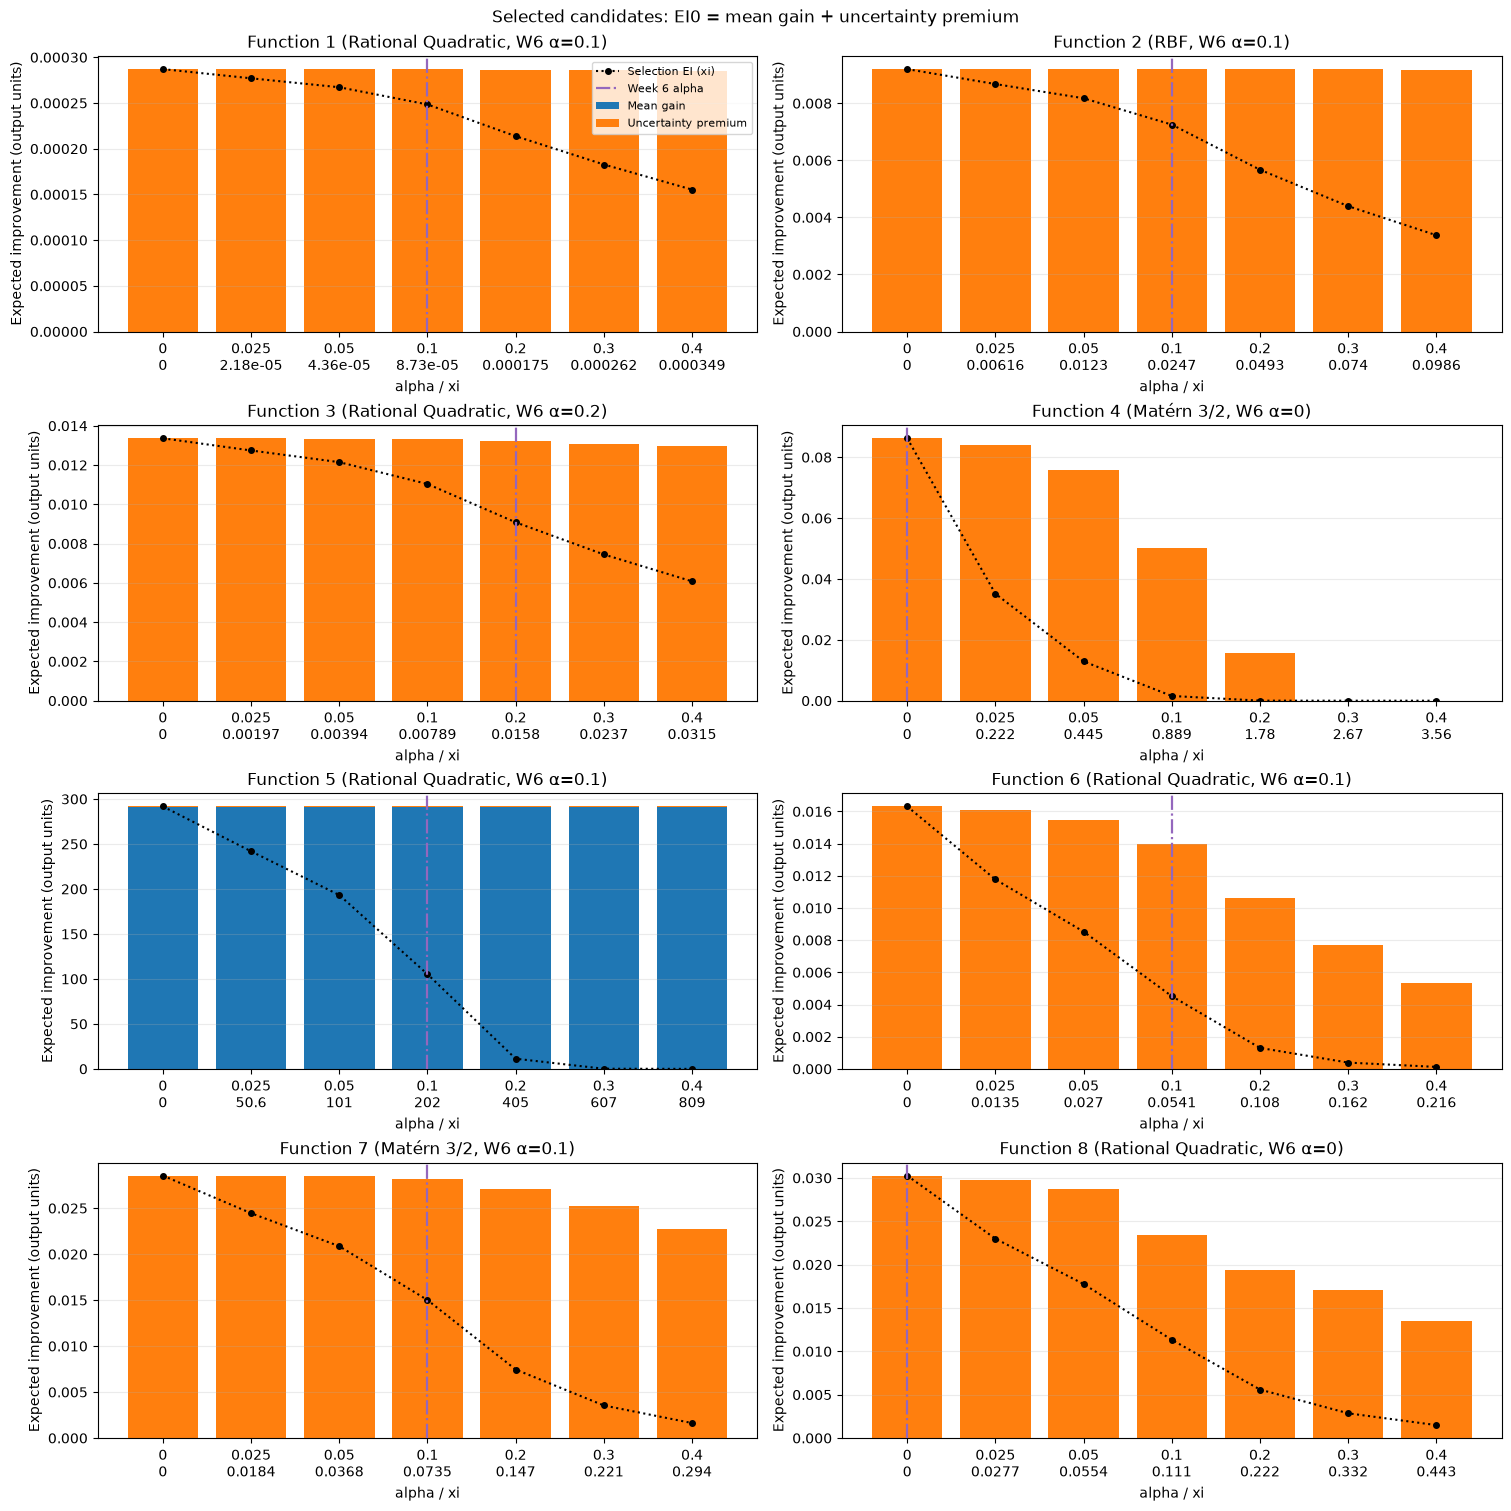

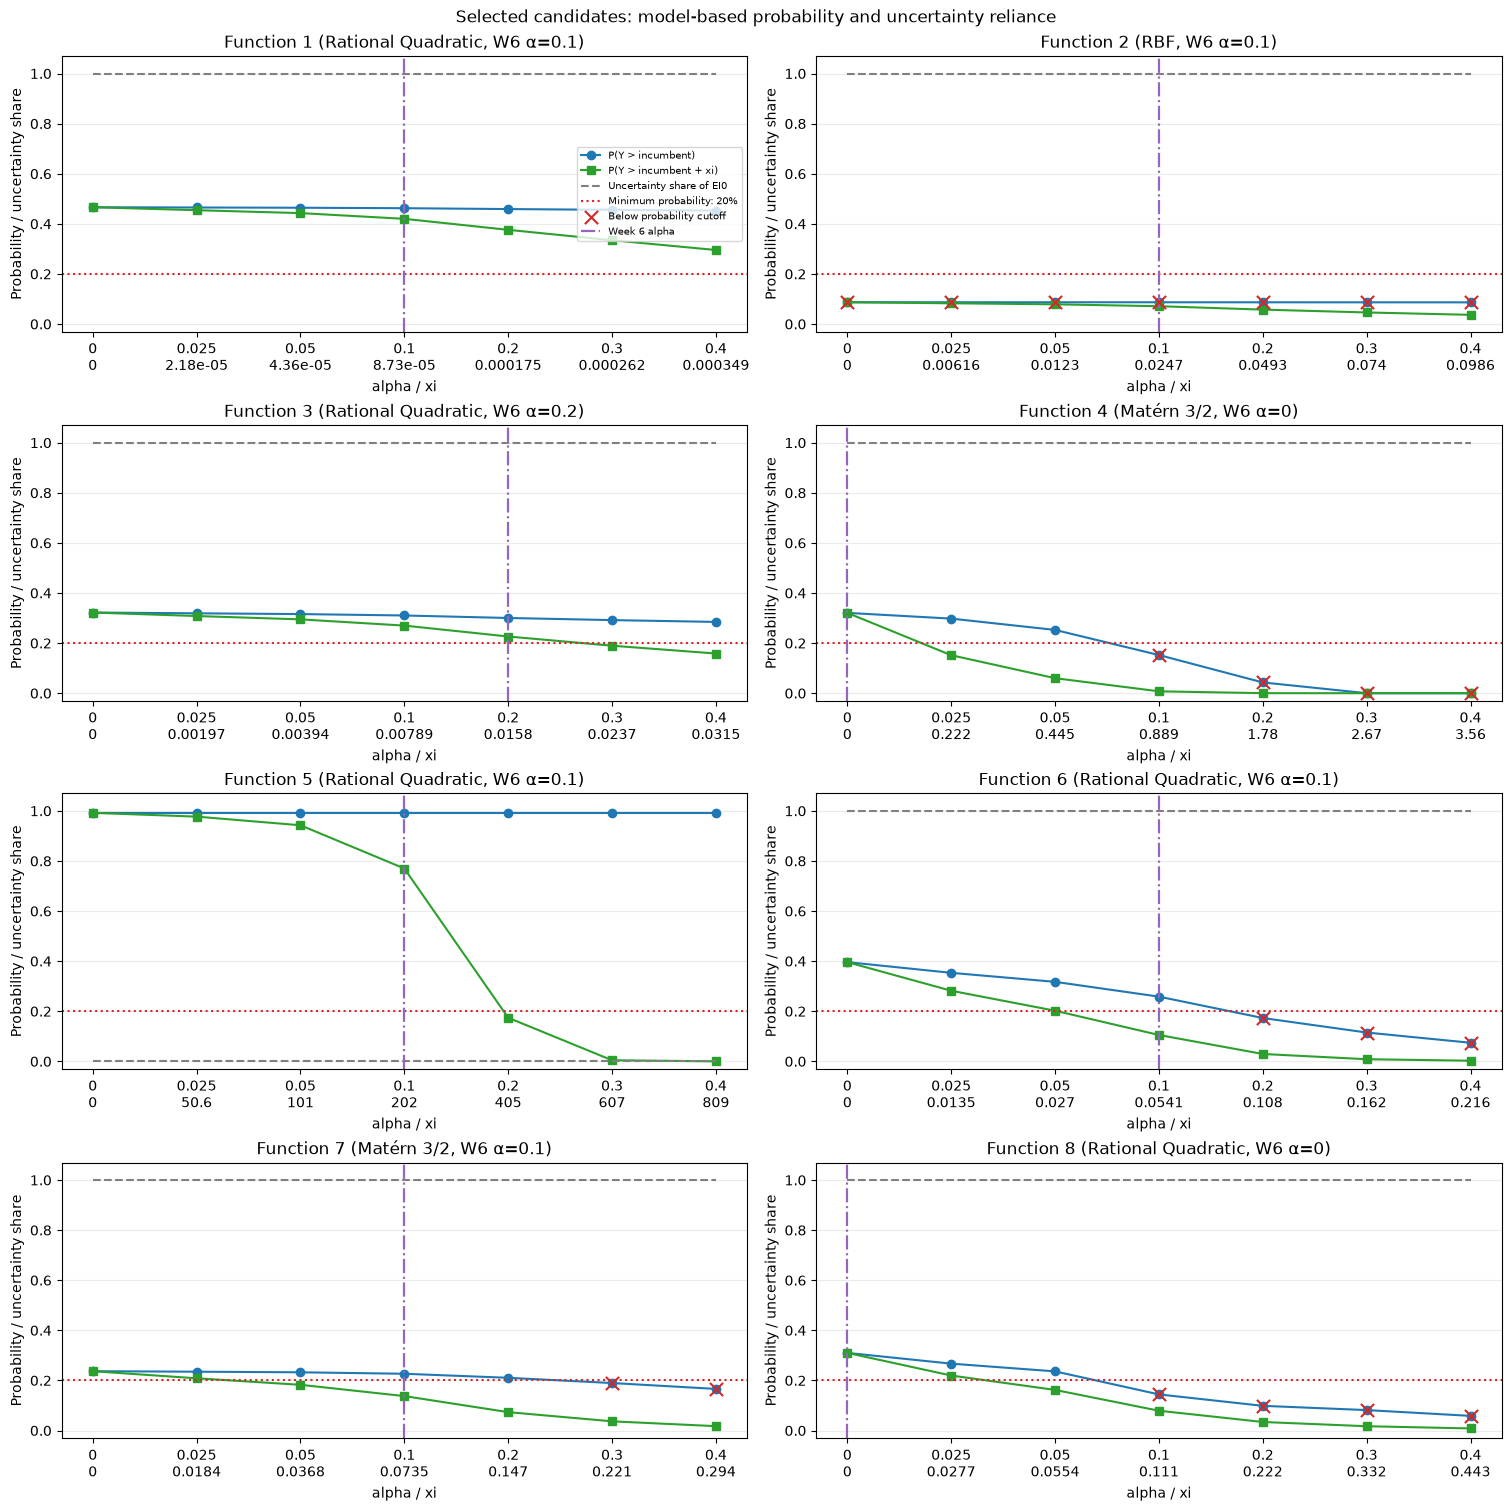

,function_id,alpha,xi,candidate,incumbent,mean,std,ei_zero,uncertainty_share,probability_improvement,below_probability_cutoff
49,8,0.000,0.000000,"(0.078306, 0.248985, 0.058345, 0.354498, 0.725...",9.976219,9.900741,0.152105,0.030263,1.0,0.309869,False
50,8,0.025,0.027707,"(0.069514, 0.23249, 0.046252, 0.384474, 0.7382...",9.976219,9.862654,0.182612,0.029720,1.0,0.267005,False
51,8,0.050,0.055413,"(0.060688, 0.205281, 0.03739, 0.414793, 0.7561...",9.976219,9.827124,0.207464,0.028717,1.0,0.236176,False
52,8,0.100,0.110826,"(0.0, 0.0, 0.048927, 0.494554, 0.888899, 0.910...",9.976219,9.639748,0.316899,0.023441,1.0,0.144172,True
53,8,0.200,0.221653,"(0.0, 0.0, 0.0, 0.620004, 0.983864, 0.999999, ...",9.976219,9.440779,0.415255,0.019335,1.0,0.098625,True
54,8,0.300,0.332479,"(0.0, 0.0, 0.0, 0.726378, 0.999999, 0.999999, ...",9.976219,9.333528,0.460912,0.017111,1.0,0.081600,True
55,8,0.400,0.443306,"(0.0, 0.0, 0.0, 0.888029, 0.999999, 0.999999, ...",9.976219,9.135069,0.536747,0.013475,1.0,0.058542,True


In [3]:
if not 0 <= MIN_PROBABILITY <= 1:
    raise ValueError("MIN_PROBABILITY must be between 0 and 1")

previous_week_rows = history.records.loc[history.records.week == CURRENT_WEEK].set_index("function_id")
previous_alphas = {}
for function_id in FUNCTION_IDS:
    settings = previous_week_rows.loc[function_id, "acquisition_settings"]
    prior_std = float(np.std(history.observations[function_id].through_week(CURRENT_WEEK - 1).outputs))
    if isinstance(settings, dict) and settings.get("name") == "ei" and prior_std > 0:
        previous_alphas[function_id] = float(settings["xi"]) / prior_std
    else:
        previous_alphas[function_id] = np.nan

gain_figure, gain_axes = plt.subplots(4, 2, figsize=(15, 15), constrained_layout=True)
risk_figure, risk_axes = plt.subplots(4, 2, figsize=(15, 15), constrained_layout=True)
for function_id, gain_ax, risk_ax in zip(FUNCTION_IDS, gain_axes.flat, risk_axes.flat):
    rows = sweep_results.loc[sweep_results.function_id == function_id].sort_values("alpha")
    alphas = rows.alpha.to_numpy(dtype=float)
    positions = np.arange(len(rows), dtype=float)
    labels = [f"{alpha:g}\n{xi:.3g}" for alpha, xi in zip(rows.alpha, rows.xi)]
    gain_ax.bar(positions, rows.mean_gain, label="Mean gain", color="tab:blue")
    gain_ax.bar(
        positions, rows.uncertainty_premium, bottom=rows.mean_gain,
        label="Uncertainty premium", color="tab:orange",
    )
    gain_ax.plot(positions, rows.selection_ei, "k:o", markersize=4, label="Selection EI (xi)")
    risk_ax.plot(positions, rows.probability_improvement, "o-", label="P(Y > incumbent)", color="tab:blue")
    risk_ax.plot(positions, rows.probability_above_threshold, "s-", label="P(Y > incumbent + xi)", color="tab:green")
    risk_ax.plot(positions, rows.uncertainty_share, "--", label="Uncertainty share of EI0", color="gray")
    risk_ax.axhline(MIN_PROBABILITY, color="tab:red", linestyle=":", label=f"Minimum probability: {MIN_PROBABILITY:.0%}")
    flagged = rows.probability_improvement.to_numpy() < MIN_PROBABILITY
    risk_ax.scatter(
        positions[flagged], rows.probability_improvement.to_numpy()[flagged],
        marker="x", color="tab:red", s=90, zorder=5, label="Below probability cutoff",
    )
    prev_alpha = previous_alphas[function_id]
    kernel_name = KERNEL_NAMES_BY_FUNCTION[function_id]
    title = f"Function {function_id} ({kernel_name})"
    if np.isfinite(prev_alpha):
        title = f"Function {function_id} ({kernel_name}, W{CURRENT_WEEK} α={round(prev_alpha, 4):g})"
        if alphas[0] <= prev_alpha <= alphas[-1]:
            prev_position = float(np.interp(prev_alpha, alphas, positions))
            for axis in (gain_ax, risk_ax):
                axis.axvline(
                    prev_position, color="tab:purple", linestyle="-.", linewidth=1.6,
                    zorder=4, label=f"Week {CURRENT_WEEK} alpha",
                )
    risk_ax.set_ylim(-0.03, 1.07)
    for axis in (gain_ax, risk_ax):
        axis.set(title=title, xlabel="alpha / xi", xticks=positions, xticklabels=labels)
        axis.grid(axis="y", alpha=0.25)
    gain_ax.set_ylabel("Expected improvement (output units)")
    risk_ax.set_ylabel("Probability / uncertainty share")
gain_axes.flat[0].legend(fontsize=8)
risk_axes.flat[0].legend(fontsize=7, loc="center right")
gain_figure.suptitle("Selected candidates: EI0 = mean gain + uncertainty premium")
risk_figure.suptitle("Selected candidates: model-based probability and uncertainty reliance")
display(gain_figure, risk_figure)
plt.close(gain_figure)
plt.close(risk_figure)

SELECTED_FUNCTION = 8
detail = sweep_results.loc[sweep_results.function_id == SELECTED_FUNCTION].copy()
detail["below_probability_cutoff"] = detail.probability_improvement < MIN_PROBABILITY
display(detail[[
    "function_id", "alpha", "xi", "candidate", "incumbent", "mean", "std",
    "ei_zero", "uncertainty_share", "probability_improvement", "below_probability_cutoff",
]])